In [7]:
#import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
#importing file
df=pd.read_csv('dropout_risk_cleaned.csv')
df

,Unnamed: 0,current_gpa,attendance_rate,study_hours_per_week,financial_stress,mental_health_score,part_time_job,parental_support,dropout_risk
0,0,3.85,81.6,15.9,6,6,1,low,0.39
1,1,4.00,58.1,18.5,5,5,1,high,0.33
2,2,2.45,78.7,18.0,6,2,0,high,0.39
3,3,1.59,66.3,27.2,1,7,0,high,0.30
4,4,3.23,64.9,26.7,9,10,0,medium,0.37
...,...,...,...,...,...,...,...,...,...
495,495,2.69,87.5,2.1,9,2,1,medium,0.51
496,496,3.38,41.8,15.9,10,5,0,low,0.56
497,497,3.14,82.3,4.0,10,8,0,medium,0.38
498,498,3.67,62.7,10.4,2,9,0,medium,0.22


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Load cleaned dataset
df = pd.read_csv("dropout_risk_cleaned.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (500, 9)


,Unnamed: 0,current_gpa,attendance_rate,study_hours_per_week,financial_stress,mental_health_score,part_time_job,parental_support,dropout_risk
0,0,3.85,81.6,15.9,6,6,1,low,0.39
1,1,4.00,58.1,18.5,5,5,1,high,0.33
2,2,2.45,78.7,18.0,6,2,0,high,0.39
3,3,1.59,66.3,27.2,1,7,0,high,0.30
4,4,3.23,64.9,26.7,9,10,0,medium,0.37


In [13]:
# Column names
print("Columns:")
print(df.columns.tolist())

# Data types and non-null values
df.info()

# Statistical summary
df.describe().T

Columns:
['Unnamed: 0', 'current_gpa', 'attendance_rate', 'study_hours_per_week', 'financial_stress', 'mental_health_score', 'part_time_job', 'parental_support', 'dropout_risk']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Unnamed: 0            500 non-null    int64  
 1   current_gpa           500 non-null    float64
 2   attendance_rate       500 non-null    float64
 3   study_hours_per_week  500 non-null    float64
 4   financial_stress      500 non-null    int64  
 5   mental_health_score   500 non-null    int64  
 6   part_time_job         500 non-null    int64  
 7   parental_support      500 non-null    object 
 8   dropout_risk          500 non-null    float64
dtypes: float64(4), int64(4), object(1)
memory usage: 35.3+ KB


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,500.0,249.500000,144.481833,0.00,124.7500,249.500000,374.250,499.00
current_gpa,500.0,2.789388,0.646882,0.53,2.3175,2.790000,3.240,4.00
attendance_rate,500.0,75.103878,13.877161,34.50,66.3750,75.103878,84.625,100.00
study_hours_per_week,500.0,15.839200,6.926096,0.00,10.9000,15.900000,20.225,33.20
financial_stress,500.0,5.506000,2.826649,1.00,3.0000,5.500000,8.000,10.00
mental_health_score,500.0,5.300000,2.829490,1.00,3.0000,5.000000,8.000,10.00
part_time_job,500.0,0.476000,0.499924,0.00,0.0000,0.000000,1.000,1.00
dropout_risk,500.0,0.394340,0.097634,0.15,0.3300,0.390000,0.460,0.68


Missing values in each column:
Series([], dtype: int64)


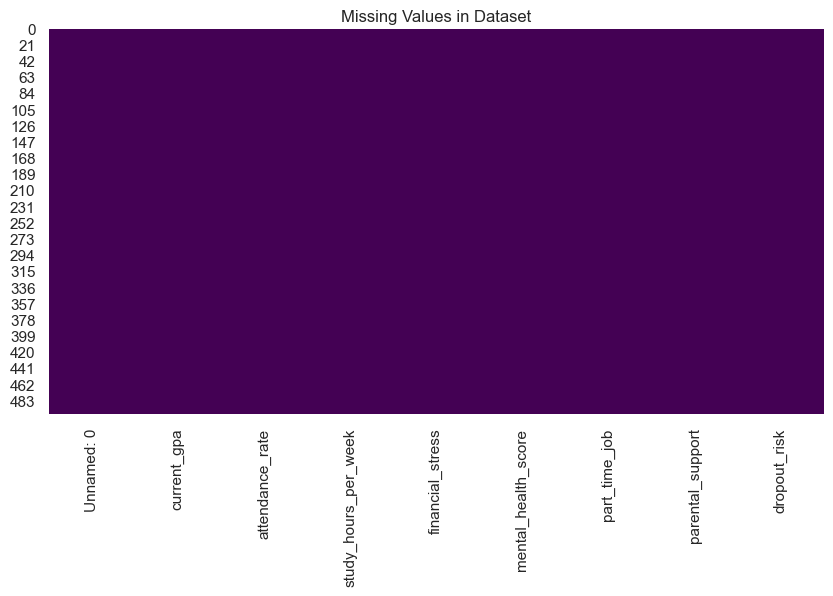

Duplicate rows: 0
Shape after removing duplicates: (500, 9)


In [14]:
# Missing values
missing = df.isnull().sum()

print("Missing values in each column:")
print(missing[missing > 0])

# Visualize missing values
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis")
plt.title("Missing Values in Dataset")
plt.show()

# Duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicates if present
df = df.drop_duplicates().copy()
print("Shape after removing duplicates:", df.shape)

In [16]:
df.columns

Index(['Unnamed: 0', 'current_gpa', 'attendance_rate', 'study_hours_per_week',
       'financial_stress', 'mental_health_score', 'part_time_job',
       'parental_support', 'dropout_risk'],
      dtype='object')

count    500.000000
mean       0.394340
std        0.097634
min        0.150000
25%        0.330000
50%        0.390000
75%        0.460000
max        0.680000
Name: dropout_risk, dtype: float64


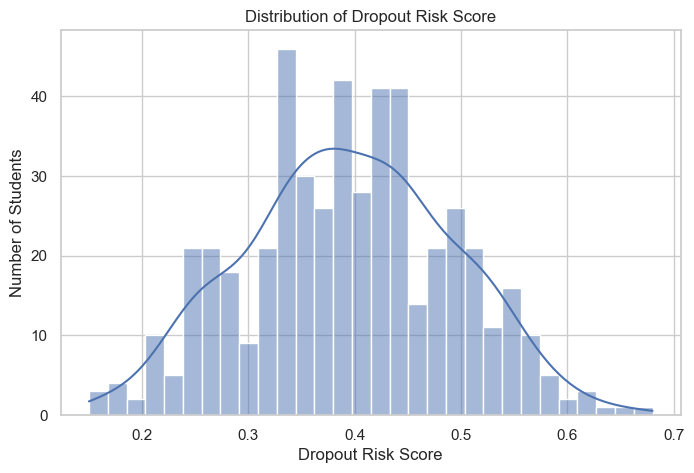

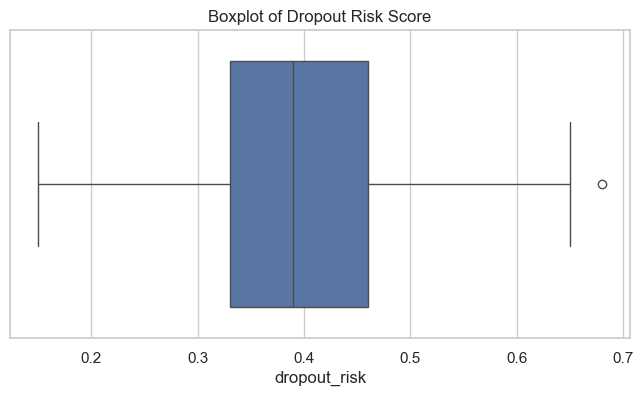

In [20]:
target = "dropout_risk"

if target in df.columns:
    print(df[target].describe())

    plt.figure(figsize=(8, 5))
    sns.histplot(df[target].dropna(), kde=True, bins=30)
    plt.title("Distribution of Dropout Risk Score")
    plt.xlabel("Dropout Risk Score")
    plt.ylabel("Number of Students")
    plt.show()

    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[target])
    plt.title("Boxplot of Dropout Risk Score")
    plt.show()
else:
    print("Target column not found. Check the column names in df.columns.")

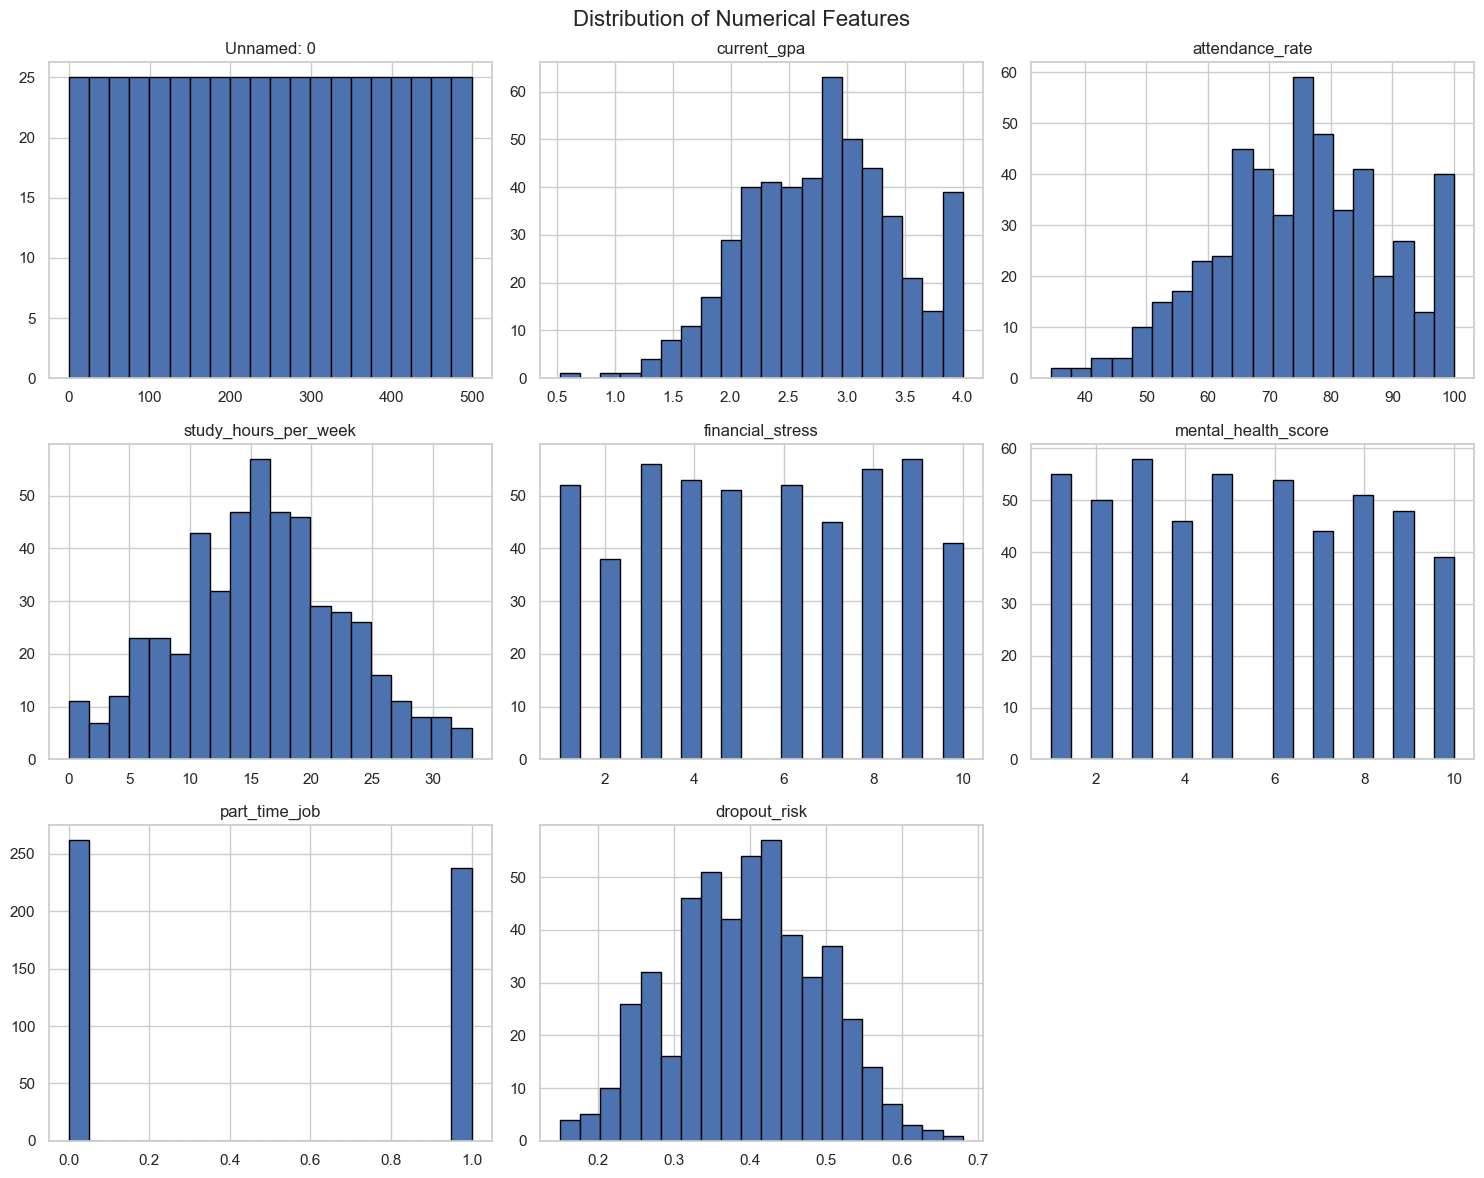

In [21]:
numeric_df = df.select_dtypes(include=np.number)

numeric_df.hist(
    figsize=(15, 12),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

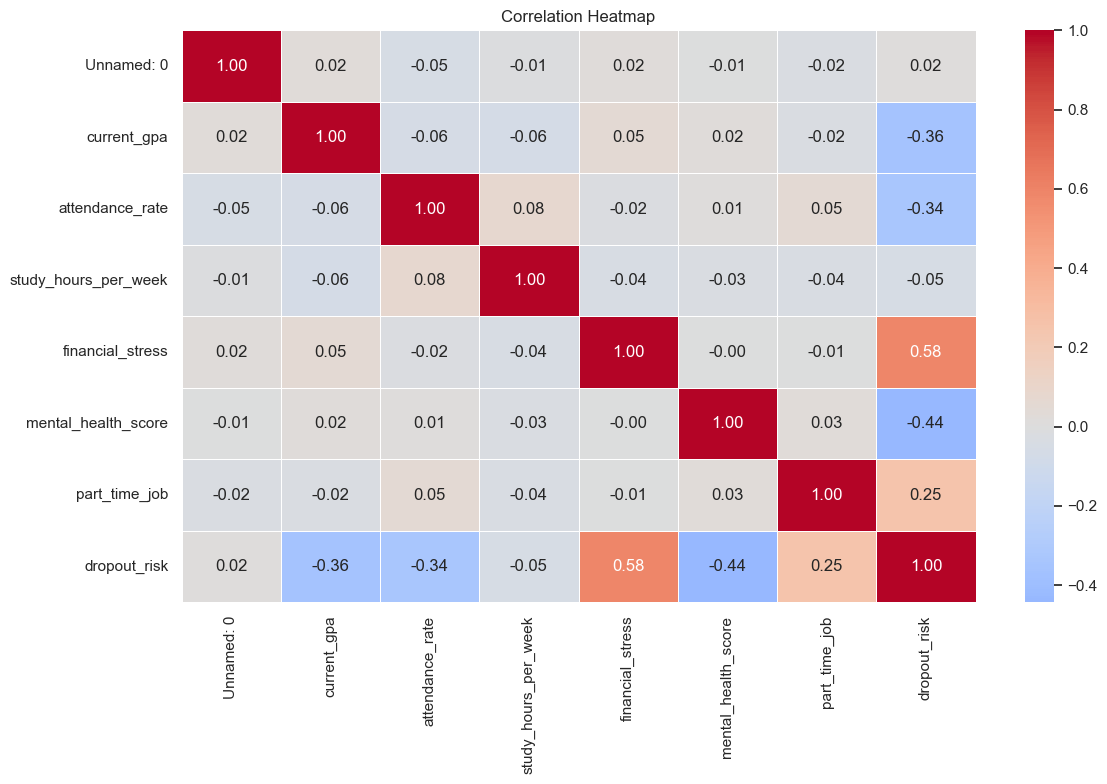

In [22]:
numeric_df = df.select_dtypes(include=np.number)

if numeric_df.shape[1] >= 2:
    plt.figure(figsize=(12, 8))

    correlation = numeric_df.corr()

    sns.heatmap(
        correlation,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        linewidths=0.5
    )

    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numerical columns for correlation analysis.")

In [23]:
target = "dropout_risk_score"

if target in numeric_df.columns:
    correlations = (
        numeric_df.corr()[target]
        .drop(target)
        .sort_values(key=abs, ascending=False)
    )

    print("Feature correlations with dropout risk:")
    print(correlations)

    correlations.plot(
        kind="bar",
        figsize=(12, 5),
        title="Feature Correlation with Dropout Risk"
    )

    plt.ylabel("Correlation Coefficient")
    plt.axhline(0, linewidth=1)
    plt.tight_layout()
    plt.show()

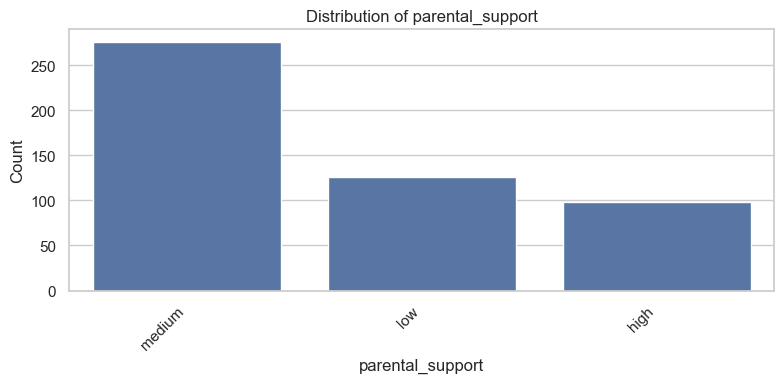

In [24]:
categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns

for col in categorical_cols:
    if df[col].nunique() <= 20:
        plt.figure(figsize=(8, 4))

        order = df[col].value_counts().index

        sns.countplot(data=df, x=col, order=order)

        plt.title(f"Distribution of {col}")
        plt.xlabel(col)
        plt.ylabel("Count")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

In [25]:
target = "dropout_risk_score"

if target in df.columns:
    features = [
        col for col in df.select_dtypes(include=np.number).columns
        if col != target
    ]

    for col in features:
        plt.figure(figsize=(7, 4))

        sns.scatterplot(data=df, x=col, y=target, alpha=0.6)

        plt.title(f"{col} vs Dropout Risk Score")
        plt.tight_layout()
        plt.show()

In [26]:
print("=" * 45)
print("EXPLORATORY DATA ANALYSIS SUMMARY")
print("=" * 45)

print("Total records:", df.shape[0])
print("Total features:", df.shape[1])
print("Duplicate rows:", df.duplicated().sum())
print("Missing values:", df.isnull().sum().sum())

print("\nNumerical columns:")
print(df.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical columns:")
print(df.select_dtypes(include=["object", "category", "bool"]).columns.tolist())

if "dropout_risk_score" in df.columns:
    print("\nDropout Risk Score Statistics:")
    print(df["dropout_risk_score"].describe())

EXPLORATORY DATA ANALYSIS SUMMARY
Total records: 500
Total features: 9
Duplicate rows: 0
Missing values: 0

Numerical columns:
['Unnamed: 0', 'current_gpa', 'attendance_rate', 'study_hours_per_week', 'financial_stress', 'mental_health_score', 'part_time_job', 'dropout_risk']

Categorical columns:
['parental_support']
